#### Se analizara a traves de la prueba de Kolmogorov & Smirnov, si dos conjuntos de datos tienen cumplen con la misma distribucion. Caso de un aeropuerto, en donde se crean datos de arribo de aeronaves de los ultimos 6 meses. de esos 6 meses dos son de temporada alta, por lo que la tasa de arribos sera diferente si se tomara los 6 meses completos incluyendo baja, y tambien evitando el horario de noche (con pocos vuelos).

## FASE 1 - crecion de datos

In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
np.random.seed(42)

In [18]:
registros = []

for dia in range(180):
    #estaciones: 0 a 120 baja - 120 a 180 alta
    regimen = 'Temporada alta' if dia >= 120 else 'Temporada baja'
    #la tasa de arribo sera de 1 aeronave cada 20 si es en alta, 45 si es baja
    tasa_media = 20.0 if regimen == 'Temporada alta' else 45.0

    tiempo_acumulado_dia = 0.0

    #ventana operativa diurna: 16 horas = 960 minutos de cada dia. 7 a 23
    while tiempo_acumulado_dia < 960.0:
        dt = np.random.gamma(shape=2.0, scale=tasa_media/2.0)
        #si el tiempo cae fuera de la ventana de 7 a 23, entonces no se lo cuenta
        if tiempo_acumulado_dia + dt > 960:
            break

        tiempo_acumulado_dia += dt
        registros.append({
            'dia': dia + 1,
            'regimen': regimen,
            'franja': 'diurna (operativa)',
            'dt_minutos': dt
        })

    salto_nocturno = (960.0 - tiempo_acumulado_dia) + 480 + np.random.normal(15.0, 5.0)
    registros.append({
        'dia': dia + 1,
        'regimen': regimen,
        'franja': 'nocturna',
        'dt_minutos': salto_nocturno
    })


df_arribos = pd.DataFrame(registros)


In [19]:
df_arribos.head()

,dia,regimen,franja,dt_minutos
0,1,Temporada baja,diurna (operativa),91.098790
1,1,Temporada baja,diurna (operativa),70.628701
2,1,Temporada baja,diurna (operativa),59.935707
3,1,Temporada baja,diurna (operativa),61.744531
4,1,Temporada baja,diurna (operativa),27.099128


In [22]:
df_diurno = df_arribos[df_arribos['franja']== 'diurna (operativa)']

baja_diurna = df_diurno[df_diurno['regimen'] == 'Temporada baja']['dt_minutos']
alta_diurna = df_diurno[df_diurno['regimen'] == 'Temporada alta']['dt_minutos']

In [23]:
alta_diurna.head(20)

2661    24.493091
2662     4.625995
2663    11.602925
2664     5.677291
2665    19.155736
2666    15.057107
2667    10.320399
2668     8.095815
2669    13.246749
2670    10.824585
2671    21.993135
2672    35.276108
2673    26.219691
2674    28.319252
2675     1.018646
2676    17.014587
2677    19.682364
2678    31.488816
2679    33.664023
2680    40.699259
Name: dt_minutos, dtype: float64

In [28]:
resumen = pd.DataFrame({
    'metrica': ['cantidad de arribos (n)', 'media (min)', 'mediana (min)', 'desvio estandar (min)', 'percentil 90 (min)'],
    'crudo 6 meses (todo mezclado)': [
        len(df_arribos),
        df_arribos['dt_minutos'].mean(),
        df_arribos['dt_minutos'].median(),
        df_arribos['dt_minutos'].std(),
        np.percentile(df_arribos['dt_minutos'], 90)
    ],
    'Temporada baja':[
        len(baja_diurna),
        baja_diurna.mean(),
        baja_diurna.median(),
        baja_diurna.std(),
        np.percentile(baja_diurna, 90)

    ],

        'Temporada alta':[
        len(alta_diurna),
        alta_diurna.mean(),
        alta_diurna.median(),
        alta_diurna.std(),
        np.percentile(alta_diurna, 90)
    ]
})

In [29]:
resumen

,metrica,crudo 6 meses (todo mezclado),Temporada baja,Temporada alta
0,cantidad de arribos (n),5538.000000,2541.000000,2817.000000
1,media (min),47.280701,43.687401,20.147624
2,mediana (min),24.493230,36.493623,16.763242
3,desvio estandar (min),91.046927,30.877447,14.112385
4,percentil 90 (min),75.013047,86.133621,39.523163


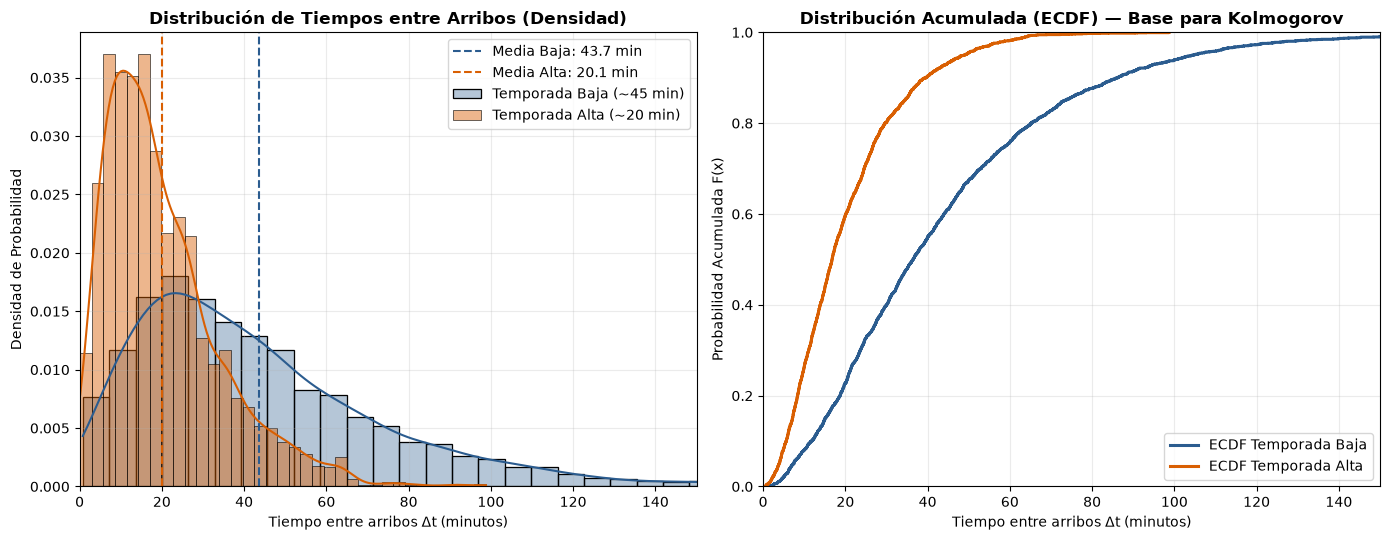

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Gráfico Izquierdo: Histograma + Curva de Densidad (KDE) ---
sns.histplot(baja_diurna, bins=35, stat='density', kde=True, color='#2b5c8f', alpha=0.35, label='Temporada Baja (~45 min)', ax=axes[0])
sns.histplot(alta_diurna, bins=35, stat='density', kde=True, color='#d95f02', alpha=0.45, label='Temporada Alta (~20 min)', ax=axes[0])

axes[0].axvline(baja_diurna.mean(), color='#2b5c8f', linestyle='--', linewidth=1.5, label=f'Media Baja: {baja_diurna.mean():.1f} min')
axes[0].axvline(alta_diurna.mean(), color='#d95f02', linestyle='--', linewidth=1.5, label=f'Media Alta: {alta_diurna.mean():.1f} min')

axes[0].set_title('Distribución de Tiempos entre Arribos (Densidad)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tiempo entre arribos Δt (minutos)')
axes[0].set_ylabel('Densidad de Probabilidad')
axes[0].set_xlim(0, 150)
axes[0].legend()
axes[0].grid(True, alpha=0.25)

# --- Gráfico Derecho: Función de Distribución Empírica Acumulada (ECDF) ---
sns.ecdfplot(baja_diurna, color='#2b5c8f', linewidth=2.2, label='ECDF Temporada Baja', ax=axes[1])
sns.ecdfplot(alta_diurna, color='#d95f02', linewidth=2.2, label='ECDF Temporada Alta', ax=axes[1])

axes[1].set_title('Distribución Acumulada (ECDF) — Base para Kolmogorov', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tiempo entre arribos Δt (minutos)')
axes[1].set_ylabel('Probabilidad Acumulada F(x)')
axes[1].set_xlim(0, 150)
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()